# A wide tube with a sparsely sampled wall

Does a wall built from separate atomic balls still behave as a tube? Here the
lumen is wide enough for two familiar probe sizes. We will establish passage,
check that the only boundary openings are at the ends, and use a much larger
probe to exclude every free center from the finite hull.

This notebook establishes the **system references without running DFND**.
Continue with [the DFND notebook](dfnd.ipynb) to ask what the native algorithm
and public `Topography` actually recover. Both notebooks run independently;
execute each from this directory in a fresh Python 3.14 kernel.

Expand code inputs on the website when useful. Run All reads frozen evidence
and recomputes its checks; it neither rewrites those files nor submits inputs.

In [1]:
from pathlib import Path
from html import escape
import hashlib
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import pyunitwizard as puw
import study

CASE = Path.cwd()
ARTIFACTS = CASE / 'artifacts/straight_tube_wide_sparse_v1'
fixture = study.read(ARTIFACTS / 'input.json')
protocol = study.read(ARTIFACTS / 'protocol.json')
assert hashlib.sha256((ARTIFACTS / 'input.json').read_bytes()).hexdigest() == protocol['input_sha256']
centers = np.asarray(puw.get_value(study.quantity(fixture['coordinates'], 'coordinates'), to_unit='angstroms'))
radii = np.asarray(puw.get_value(study.quantity(fixture['atom_radii'], 'atom_radii'), to_unit='angstroms'))
assert centers.shape == (77, 3) and np.allclose(radii, 1.88, rtol=0, atol=1e-14)
assert fixture['source_atom_indices'] == list(range(77))

def table(headers, rows):
    def cells(values, tag):
        return ''.join(f'<{tag}>{escape(str(value))}</{tag}>' for value in values)
    display(HTML('<table><thead><tr>' + cells(headers, 'th') +
                 '</tr></thead><tbody>' + ''.join('<tr>' + cells(row, 'td') +
                 '</tr>' for row in rows) + '</tbody></table>'))

assert 'topomt' not in sys.modules

## The atomic system

Seven perturbed rings, each containing eleven argon balls, surround the z axis.
The nominal ring radius is 6 Å, the end-to-end center length is 20 Å, and the
nominal sampling parameter is 3.5 Å. The actual axial ring separation is 20/6 Å;
the generator chooses integer ring/column counts. Each atom has radius 1.88 Å.
A fixed seed of zero and jitter parameter 0.1 define the retained realization.

The full-precision, quantity-aware `input.json` defines the geometry. Its PDB
companion supplies topology; using its rounded coordinates as the geometry
would change this experiment. Source atom IDs are 0–76.

We use the **convex hull of atomic centers as a finite carrier**, with isolated,
nonperiodic conditions. A probe center is strictly free when its distance to
every atom center exceeds the atom radius plus the probe radius. The unbounded
exterior remains part of the surrounding space, even when that finite carrier
is completely covered.

In [2]:
refs = study.references(CASE)
passage = refs['passage']
model = passage['model_reference']
assert 'topomt' not in sys.modules
assert passage['path_minimum_clearance_angstroms'] > 2.5 + 1e-6
table(['Probe (Å)', 'Fixed axis', 'End-to-end witness', 'Whole finite hull'], [
    [r['probe_angstroms'], r['fixed_axis'], r['end_to_end_path'], r['finite_hull']]
    for r in passage['controls']])

Probe (Å),Fixed axis,End-to-end witness,Whole finite hull
1.4,clear,certified,not_established
2.5,clear,certified,not_established
5.0,blocked,not_established,strictly_covered


## First reference: a continuous passage

The axis itself supplies a complete end-to-end witness for 1.4 and 2.5 Å probes.
For each full line segment, the checker projects every atom center onto the
segment and evaluates the clamped closest point. It takes the smallest clearance
over **all atoms and every complete segment**, rather than checking just a few
waypoints. Both terminal points lie beyond all atomic z coordinates, so distance
to every atom increases along the two outward infinite axial rays.

The minimum clearance is **3.906596981 Å**: a margin of 2.506596981 Å at 1.4 Å,
and 1.406596981 Å at 2.5 Å. This proves one physical route through the system.
It does not identify the globally optimal bottleneck or count all connected
three-dimensional free regions.

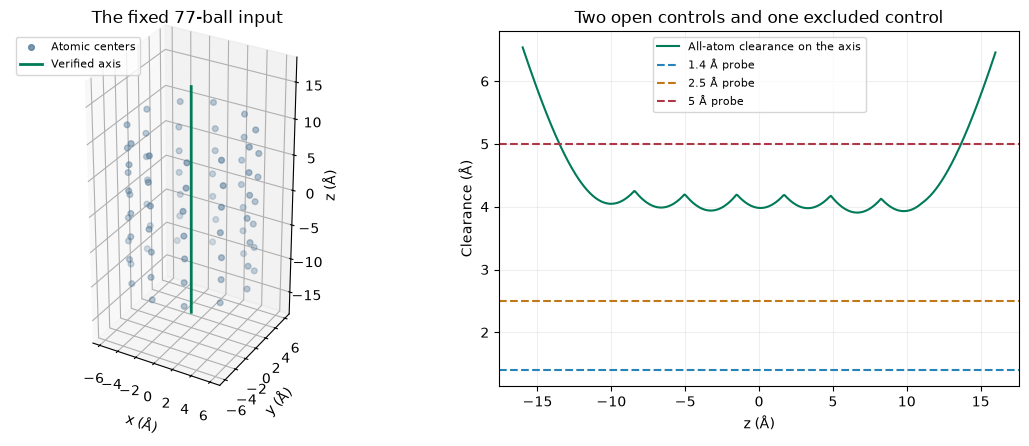

In [3]:
z = np.linspace(-16, 16, 501)
points = np.column_stack([np.zeros_like(z), np.zeros_like(z), z])
clearance = (np.linalg.norm(points[:, None, :] - centers[None, :, :], axis=2) - radii).min(axis=1)
fig = plt.figure(figsize=(11, 4.3), layout='constrained')
ax = fig.add_subplot(121, projection='3d')
ax.scatter(*centers.T, s=17, color='#507695', alpha=.75, label='Atomic centers')
ax.plot([0, 0], [0, 0], [-16, 16], color='#007a58', lw=2, label='Verified axis')
ax.set(xlabel='x (Å)', ylabel='y (Å)', zlabel='z (Å)', title='The fixed 77-ball input')
ax.set_box_aspect((1, 1, 2)); ax.legend(fontsize=8, loc='upper left')
ax = fig.add_subplot(122)
ax.plot(z, clearance, color='#007a58', label='All-atom clearance on the axis')
for probe, color in [(1.4, '#2784b9'), (2.5, '#bf791a'), (5, '#ad3746')]:
    ax.axhline(probe, color=color, ls='--', label=f'{probe:g} Å probe')
ax.set(xlabel='z (Å)', ylabel='Clearance (Å)', title='Two open controls and one excluded control')
ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.show()

Markers in the left panel show atomic **centers**, not ball radii. The plotted
clearance samples make the geometry readable; the continuous segment calculation,
not this plotted grid, certifies the minimum.

## Second reference: two ends, with no lateral opening

A path alone would not rule out a leak through the wall. A separate checker
therefore inspects the **complete triangulated hull**. It proves each lateral
triangle covered by expanded balls, resolves free regions in the end triangles,
and joins them through independently checked seams and vertices. The retained
certificates contain the covering subdivisions and geometric witnesses needed
to replay that proof. They import no DFND routine.

In [4]:
rows = []
for probe in (1.4, 2.5):
    result = refs['boundary'][str(probe)]
    assert result['opening_component_count'] == 2
    assert sorted(result['component_end_labels']) == ['negative_z', 'positive_z']
    rows.append([probe, result['complete_hull_faces'], result['covered_wall_faces'],
                 result['end_faces'], result['free_end_faces'], result['free_seams'],
                 result['opening_component_count']])
table(['Probe (Å)', 'Hull faces', 'Covered wall faces', 'End faces',
       'Free end faces', 'Free seams', 'Physical patches'], rows)

Probe (Å),Hull faces,Covered wall faces,End faces,Free end faces,Free seams,Physical patches
1.4,86,68,18,6,4,2
2.5,86,68,18,4,2,2


Both probes give exactly **two strict-free hull patches**, one at each end.
The 68 lateral faces are all covered. The nominally sparse sampling therefore
does **not** imply physical side openings at these probe sizes. Counts of free
triangles (six versus four) and seams (four versus two) describe a triangulation;
they are not counts of openings. Nor does this boundary proof exclude a buried
free island that never touches the hull.

## Third reference: excluding the finite carrier

At 5 Å, we do not infer closure merely because the axis is blocked. A sufficient
cover bound applies to **every point of the finite hull**. Hull convexity bounds
its radial and axial extent; the nearest nominal ring/column bounds the distance
to a grid atom; the measured maximum perturbation adds a conservative correction.

The resulting actual-atom distance bound is **6.594243009 Å**, below the expanded
radius 1.88 + 5 = **6.88 Å** by **0.285756991 Å**. Thus no strict-free center
exists anywhere in the finite hull. Unbounded exterior space still exists.

In [5]:
excluded = model['exclusion']['5.0']
assert excluded['strictly_covered']
assert excluded['coverage_margin_angstroms'] > 1e-6
table(['Quantity', 'Value (Å)'], [
    ['Axis minimum clearance', passage['path_minimum_clearance_angstroms']],
    ['Maximum atomic perturbation', model['maximum_nominal_displacement_angstroms']],
    ['Finite-hull distance upper bound', model['finite_hull_cover_distance_bound_angstroms']],
    ['5 Å expanded-ball radius', 6.88],
    ['Finite-hull cover margin', excluded['coverage_margin_angstroms']]])
assert 'topomt' not in sys.modules
print('Independent references replayed; DFND was not imported.')

Quantity,Value (Å)
Axis minimum clearance,3.9065969808290815
Maximum atomic perturbation,0.36706244540940697
Finite-hull distance upper bound,6.594243009499208
5 Å expanded-ball radius,6.88
Finite-hull cover margin,0.28575699050079173


Independent references replayed; DFND was not imported.


## What to expect from DFND

The next notebook tests the same ball model at 1.4, 2.5 and 5 Å. The first two
controls should support passage and two physical boundary patches. The last
has no all-atom free center in the carrier. Local graph components, catalog
classes, public Mouth children and physical patches must be inspected separately.

Compared with the [narrow tube](../straight_tube_narrow_dense/system.ipynb),
both the radius and the sampling change. At the shared 2.5 Å probe the narrow
carrier is covered, while this wider tube has a verified passage. That is a
useful paired diagnostic, **not an experiment isolating sampling density**.

This existing catalog input was known during development. These are independently
justified, retrospective controls, not a blind evaluation panel. Exact volume,
aperture area, optimal paths and biological performance are outside this unit.
The [evidence guide](artifacts/straight_tube_wide_sparse_v1/README.md) gives hashes,
protocol chronology, resource bounds and the download/replay route.